In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics as skm
np.random.seed(2026)
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp                    
from sklearn import datasets
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [23]:
def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn

def classification_report(y_true, y_pred):
    # accuracy, precision, recall and F1 from the four counts
    tp, fn, fp, tn = confusion_matrix(y_true, y_pred)
    n = tp + fn + fp + tn
    accuracy = (tp + tn) / n
    precision = tp / (tp + fp) if tp + fp else 0.0          # of those flagged positive, how many were?
    recall = tp / (tp + fn) if tp + fn else 0.0             # of the positives, how many did we find? (= TPR)
    specificity = tn / (tn + fp) if tn + fp else 0.0        # of the negatives, how many did we leave alone? (= 1 - FPR)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    balanced = 0.5 * (recall + specificity)
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = ((tp * tn - fp * fn) / denom) if denom else 0.0  # Matthews correlation coefficient: correlation of y and y_hat
    return dict(TP=tp, FN=fn, FP=fp, TN=tn, accuracy=accuracy, precision=precision, recall=recall,
                specificity=specificity, f1=f1, balanced_accuracy=balanced, mcc=mcc)


In [24]:

def roc_curve(y_true, scores):
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    y, s = y_true[order], scores[order]
    tp, fp = np.cumsum(y == 1), np.cumsum(y == 0)
    last = np.r_[np.diff(s) != 0, True]            # one point per distinct threshold
    tpr = np.r_[0.0, tp[last] / max(tp[-1], 1)]
    fpr = np.r_[0.0, fp[last] / max(fp[-1], 1)]
    thresholds = np.r_[np.inf, s[last]]
    return fpr, tpr, thresholds

def auc_trapezoid(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))

def roc_auc(y_true, scores):
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    _, inv, cnt = np.unique(scores, return_inverse=True, return_counts=True)
    first = np.cumsum(cnt) - cnt + 1                  # rank of the first member of each tie group
    ranks = (first + (cnt - 1) / 2)[inv]              # average rank within the group
    n_pos = int(np.sum(y_true == 1))
    n_neg = len(y_true) - n_pos
    S = np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2
    return float(S / (n_pos * n_neg))


# a small test: 20 samples, 6 positives, scores rounded to one decimal so that there are ties
rng = np.random.default_rng(2)
y_small = np.array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0])
s_small = np.round(np.clip(0.35 * y_small + rng.normal(0.3, 0.2, 20), 0, 1), 1)
print(confusion_matrix(y_small, s_small > 0.5), skm.confusion_matrix(y_small, s_small > 0.5))
print(roc_auc(y_small, s_small), auc_trapezoid(*roc_curve(y_small, s_small)[:2]), skm.roc_auc_score(y_small, s_small))

(5, 1, 1, 13) [[13  1]
 [ 1  5]]
0.8571428571428571 0.8571428571428572 0.8571428571428571


[[13  1]
 [ 1  5]]
accuracy 0.9000  precision 0.8333  recall 0.8333  F1 0.8333
              precision    recall  f1-score   support

    negative       0.93      0.93      0.93        14
    positive       0.83      0.83      0.83         6

    accuracy                           0.90        20
   macro avg       0.88      0.88      0.88        20
weighted avg       0.90      0.90      0.90        20

AUC 0.8571


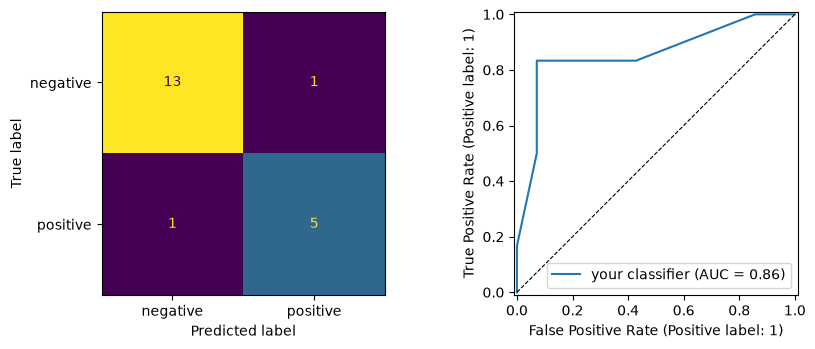

In [25]:
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

y_test, p_test = y_small, s_small          # replace by your test labels and output probabilities
y_pred = p_test > 0.5

cm = sk_confusion_matrix(y_test, y_pred)   # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred):.4f}  precision {precision_score(y_test, y_pred, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred):.4f}  F1 {f1_score(y_test, y_pred):.4f}")
print(sk_classification_report(y_test, y_pred, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.tight_layout(); plt.show()

In [26]:
def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)



ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}


def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def accuracy(X, y, layers, hidden_activation, head):
    """Fraction of correct labels; y holds integer labels for softmax, 0/1 for binary."""
    out = predict(X, layers, hidden_activation, head)
    if head == "softmax":
        return np.mean(np.argmax(out, axis=1) == y)
    return np.mean((out[:, 0] > 0.5) == (y > 0.5))


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history


def one_hot(y, n_classes=None):
    """Integer labels -> one-hot rows."""
    n_classes = int(np.max(y)) + 1 if n_classes is None else n_classes
    Y = np.zeros((len(y), n_classes))
    Y[np.arange(len(y)), y] = 1.0
    return Y

train 60000, test 10000 images
fraction of threes: train 0.102, test 0.101
accuracy of 'never a three' on the test set: 0.8990


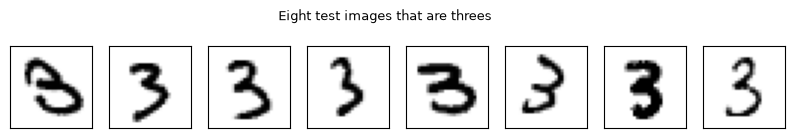

Report the prevalence of 3 in the test set and the accuracy of the majority rule: whatever you make the test/training size, the images are always very accurate, and the fraction of threes identified is always 0.1 to 2 dp. Accuracy of never a three is always 0.9 to 2 dp also, which shows us that the model is very competent.


In [27]:
# Task 2 a)

# loading whole dataset this time
with np.load("./data/mnist.npz") as data:
    x_train = data["x_train"]
    y_train_original = data["y_train"]
    x_test = data["x_test"]
    y_test_original = data["y_test"]

d = 3  
x_train = x_train.reshape(len(x_train), -1) / 255.0
x_test = x_test.reshape(len(x_test), -1) / 255.0

# Binary labels: 1 if the image is a 3, otherwise 0
y_train = (y_train_original == d).astype(float)
y_test = (y_test_original == d).astype(float)

print(f"train {len(y_train)}, test {len(y_test)} images")
print(f"fraction of threes: train {y_train.mean():.3f}, test {y_test.mean():.3f}")
print(f"accuracy of 'never a three' on the test set: {1 - y_test.mean():.4f}")

fig, ax = plt.subplots(1, 8, figsize=(10, 1.6))
for a, i in zip(ax, np.where(y_test == 1)[0][:8]):
    a.imshow(x_test[i].reshape(28, 28), cmap="gray_r")
    a.set_xticks([])
    a.set_yticks([])

fig.suptitle("Eight test images that are threes", fontsize=9)
plt.show()

print("Report the prevalence of 3 in the test set and the accuracy of the majority rule: whatever you make the test/training size, the images are always very accurate, and the fraction of threes identified is always 0.1 to 2 dp. Accuracy of never a three is always 0.9 to 2 dp also, which shows us that the model is very competent.")


In [28]:
print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

x_train: (60000, 784)
y_train: (60000,)
x_test: (10000, 784)
y_test: (10000,)


logistic regression: 785 parameters, final cost 0.0783, test accuracy 0.9763
one hidden layer of 32: 25153 parameters, final cost 0.0001, test accuracy 0.9941


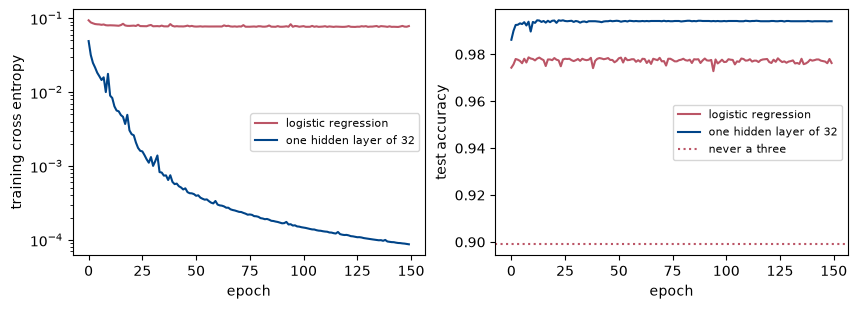

In [29]:

BLUE, RED, YELLOW, GREY = "#004488", "#BB5566", "#DDAA33", "#777777"
GREEN = "#228833"

models = {}
for name, sizes, act in (("logistic regression", [x_train.shape[1], 1], "sigmoid"),
                         ("one hidden layer of 32", [x_train.shape[1], 32, 1], "relu")):
    layers = create_layers(sizes, act, np.random.default_rng(2026))
    layers, hist = train(x_train, y_train[:, None], layers, act, "binary", gamma=0.1, epochs=150,
                         batch_size=32, X_test=x_test, y_test=y_test)
    models[name] = {"layers": layers, "act": act, "history": hist,
                    "p_test": predict(x_test, layers, act, "binary")[:, 0],
                    "n_params": sum(W.size + b.size for W, b in layers)}
    print(f"{name}: {models[name]['n_params']} parameters, final cost {hist['cost'][-1]:.4f}, "
          f"test accuracy {hist['test_accuracy'][-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for name, col in zip(models, (RED, BLUE)):
    ax[0].semilogy(models[name]["history"]["cost"], color=col, label=name)
    ax[1].plot(models[name]["history"]["test_accuracy"], color=col, label=name)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training cross entropy"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("test accuracy"); ax[1].axhline(1 - y_test.mean(), color=RED, ls=":", label="never a three")
ax[1].legend(fontsize=8)
plt.show()

In [30]:
# b)
for name in models:
    p = models[name]["p_test"]
    r = classification_report(y_test, p > 0.5)
    print(f"--- {name}, t = 0.5")
    print(f"  TP {r['TP']}  FN {r['FN']}  FP {r['FP']}  TN {r['TN']}")
    print(f"  accuracy {r['accuracy']:.4f}  precision {r['precision']:.4f}  recall {r['recall']:.4f}  specificity {r['specificity']:.4f}")
    print(f"  F1 {r['f1']:.4f}  balanced accuracy {r['balanced_accuracy']:.4f}  MCC {r['mcc']:.4f}")
    print(f"  fraction of the remaining error removed: {1 - (1 - r['accuracy']) / y_test.mean():.3f}")
    print(f"  sklearn confusion_matrix:\n{skm.confusion_matrix(y_test, p > 0.5)}")
    print(f"  sklearn precision {skm.precision_score(y_test, p > 0.5):.4f}  recall {skm.recall_score(y_test, p > 0.5):.4f}  "
          f"F1 {skm.f1_score(y_test, p > 0.5):.4f}  MCC {skm.matthews_corrcoef(y_test, p > 0.5):.4f}")

print("\n What do the matrices tell you that the two accuracies do not? \n They outline the exact values which mean its easier to see whether the model is just 'accurate' because it predicts everything true and luckily they are mostly true anyway.")
print("\n What fraction of the remaining error (relative to the majority rule) does each classifier remove? \n For logistic regression, 0.765, for one hidden layer, 0.942")

--- logistic regression, t = 0.5
  TP 837  FN 173  FP 64  TN 8926
  accuracy 0.9763  precision 0.9290  recall 0.8287  specificity 0.9929
  F1 0.8760  balanced accuracy 0.9108  MCC 0.8646
  fraction of the remaining error removed: 0.765
  sklearn confusion_matrix:
[[8926   64]
 [ 173  837]]
  sklearn precision 0.9290  recall 0.8287  F1 0.8760  MCC 0.8646
--- one hidden layer of 32, t = 0.5
  TP 977  FN 33  FP 26  TN 8964
  accuracy 0.9941  precision 0.9741  recall 0.9673  specificity 0.9971
  F1 0.9707  balanced accuracy 0.9822  MCC 0.9674
  fraction of the remaining error removed: 0.942
  sklearn confusion_matrix:
[[8964   26]
 [  33  977]]
  sklearn precision 0.9741  recall 0.9673  F1 0.9707  MCC 0.9674

 What do the matrices tell you that the two accuracies do not? 
 They outline the exact values which mean its easier to see whether the model is just 'accurate' because it predicts everything true and luckily they are mostly true anyway.

 What fraction of the remaining error (relativ

In [31]:
#c)

def roc_curve(y_true, scores):
    """False and true positive rates as the threshold sweeps down through every distinct score.

    Sorting the scores once gives every point of the curve in O(n log n):
    walking down the sorted list, each sample flagged positive adds one to
    TP (if it is a positive) or to FP (if it is a negative).
    """
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    y, s = y_true[order], scores[order]
    tp, fp = np.cumsum(y == 1), np.cumsum(y == 0)
    last = np.r_[np.diff(s) != 0, True]            # one point per distinct threshold
    tpr = np.r_[0.0, tp[last] / max(tp[-1], 1)]
    fpr = np.r_[0.0, fp[last] / max(fp[-1], 1)]
    thresholds = np.r_[np.inf, s[last]]
    return fpr, tpr, thresholds


def auc_trapezoid(fpr, tpr):
    """The area under the ROC curve by the trapezoidal rule."""
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))


def roc_auc(y_true, scores):
    """The AUC as the probability that a random positive outranks a random negative (Section 5.12), from the ranks.

    Tied scores get the average of the ranks they span, so that a tie between
    a positive and a negative counts half a pair -- which is also what the
    trapezoidal rule does along a tie segment of the ROC curve.
    """
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    _, inv, cnt = np.unique(scores, return_inverse=True, return_counts=True)
    first = np.cumsum(cnt) - cnt + 1                  # rank of the first member of each tie group
    ranks = (first + (cnt - 1) / 2)[inv]              # average rank within the group
    n_pos = int(np.sum(y_true == 1))
    n_neg = len(y_true) - n_pos
    S = np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2
    return float(S / (n_pos * n_neg))

logistic regression: AUC trapezoid 0.98509, ranks 0.98509, sklearn 0.98509; ROC curve: 10001 points, identical to sklearn's: True
one hidden layer of 32: AUC trapezoid 0.99926, ranks 0.99926, sklearn 0.99926; ROC curve: 9888 points, identical to sklearn's: True


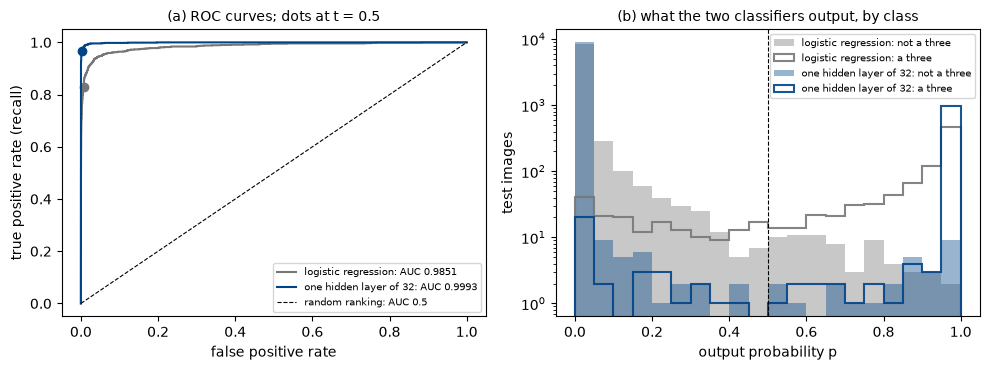

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for name, col in zip(models, (GREY, BLUE)):
    p = models[name]["p_test"]
    fpr, tpr, thr = roc_curve(y_test, p)
    auc_t, auc_r, auc_s = auc_trapezoid(fpr, tpr), roc_auc(y_test, p), skm.roc_auc_score(y_test, p)
    fpr_s, tpr_s, _ = skm.roc_curve(y_test, p, drop_intermediate=False)   # sklearn drops collinear points by default
    print(f"{name}: AUC trapezoid {auc_t:.5f}, ranks {auc_r:.5f}, sklearn {auc_s:.5f}; "
          f"ROC curve: {len(fpr)} points, identical to sklearn's: {np.allclose(fpr, fpr_s) and np.allclose(tpr, tpr_s)}")
    ax[0].plot(fpr, tpr, color=col, lw=1.5, label=f"{name}: AUC {auc_r:.4f}")
    k = np.searchsorted(-thr, -0.5)
    ax[0].plot(fpr[min(k, len(fpr) - 1)], tpr[min(k, len(tpr) - 1)], "o", color=col)
    bins = np.linspace(0, 1, 21)
    ax[1].hist(p[y_test == 0], bins=bins, color=col, alpha=0.4, label=f"{name}: not a three")
    ax[1].hist(p[y_test == 1], bins=bins, color=col, alpha=0.9, histtype="step", lw=1.5, label=f"{name}: a three")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="random ranking: AUC 0.5")
ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate (recall)"); ax[0].legend(fontsize=7)
ax[0].set_title("(a) ROC curves; dots at t = 0.5", fontsize=10)
ax[1].axvline(0.5, color="k", ls="--", lw=0.8)
ax[1].set_yscale("log"); ax[1].set_xlabel("output probability p"); ax[1].set_ylabel("test images"); ax[1].legend(fontsize=7)
ax[1].set_title("(b) what the two classifiers output, by class", fontsize=10)
plt.tight_layout(); plt.show()

Most images are correct, with non-threes near 0 and threes near 1. The errors live mostly at the edges of the output probability at the other end. The hidden layer performed better than the logistic regression.

The hidden layer with an AUC of 0.99993 has misordered about 3 orders of magnitude digits fewer than the logistic regression.

In [33]:
# d) Standard errors: of the test accuracy and of the recall (Eq. 2.24,...  with the appropriate in each case). Would you call the difference between your two classifiers significant?

n_test = len(y_test) # all test images
n_pos = int(np.sum(y_test == 1)) # only the real threes

se = {}
for name in models:
    pred = models[name]["p_test"] > 0.5
    acc = np.mean(pred == y_test)
    rec = np.mean(pred[y_test == 1])
    se_acc = np.sqrt(acc * (1 - acc) / n_test)
    se_rec = np.sqrt(rec * (1 - rec) / n_pos)
    se[name] = (acc, se_acc, rec, se_rec)
    print(f"{name}: accuracy {acc:.4f} ± {se_acc:.4f}, recall {rec:.4f} ± {se_rec:.4f}")

(acc1, sa1, rec1, sr1), (acc2, sa2, rec2, sr2) = se.values()

diff_acc = acc2 - acc1
diff_rec = rec2 - rec1
se_diff_acc = np.sqrt(sa1**2 + sa2**2)
se_diff_rec = np.sqrt(sr1**2 + sr2**2)
print(f"accuracy difference {diff_acc:.4f} = {diff_acc / se_diff_acc:.1f} standard errors")
print(f"recall difference {diff_rec:.4f} = {diff_rec / se_diff_rec:.1f} standard errors")
print("The difference in accuracy and recall is more than 10 standard errors, which is highly significant, so the one hidden layer model is significantly better than logistic regression for this task.")

logistic regression: accuracy 0.9763 ± 0.0015, recall 0.8287 ± 0.0119
one hidden layer of 32: accuracy 0.9941 ± 0.0008, recall 0.9673 ± 0.0056
accuracy difference 0.0178 = 10.5 standard errors
recall difference 0.1386 = 10.6 standard errors
The difference in accuracy and recall is more than 10 standard errors, which is highly significant, so the one hidden layer model is significantly better than logistic regression for this task.


## Declaration of the use of LLMs

AI tools (Claude Sonnet 5.5) were used only in exercise 2d) to finish and debug existing code. Everything else was completed without AI tools.